In [22]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from src.tools.data_loader import get_dataloader, get_dataset_info

## Configuration

In [23]:
# Choose dataset: 'mnist', 'fashion_mnist', or 'cifar10'
DATASET_NAME = 'mnist'
BATCH_SIZE = 64
DATA_DIR = './data'

## Load Dataset

In [24]:
# Get dataset info
info = get_dataset_info(DATASET_NAME)
print(f"Dataset: {info['name']}")
print(f"Description: {info['description']}")
print(f"Number of classes: {info['num_classes']}")
print(f"Image shape: {info['image_shape']}")
print(f"Training samples: {info['num_train']}")
print(f"Test samples: {info['num_test']}")
print(f"Grayscale: {info['grayscale']}")

Dataset: MNIST
Description: Handwritten digits (0-9)
Number of classes: 10
Image shape: (1, 28, 28)
Training samples: 60000
Test samples: 10000
Grayscale: True


In [25]:
# Load dataloaders
train_loader, num_classes, image_shape = get_dataloader(
    dataset_name=DATASET_NAME,
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    train=True,
    shuffle=True
)

test_loader, _, _ = get_dataloader(
    dataset_name=DATASET_NAME,
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    train=False,
    shuffle=False
)

print(f"\nTrain batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")


Train batches: 938
Test batches: 157


## Visualize Sample Images

In [5]:
# Get a batch of images
images, labels = next(iter(train_loader))

print(f"Batch shape: {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Image dtype: {images.dtype}")
print(f"Image range: [{images.min():.3f}, {images.max():.3f}]")

Batch shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Image dtype: torch.float32
Image range: [-1.000, 1.000]


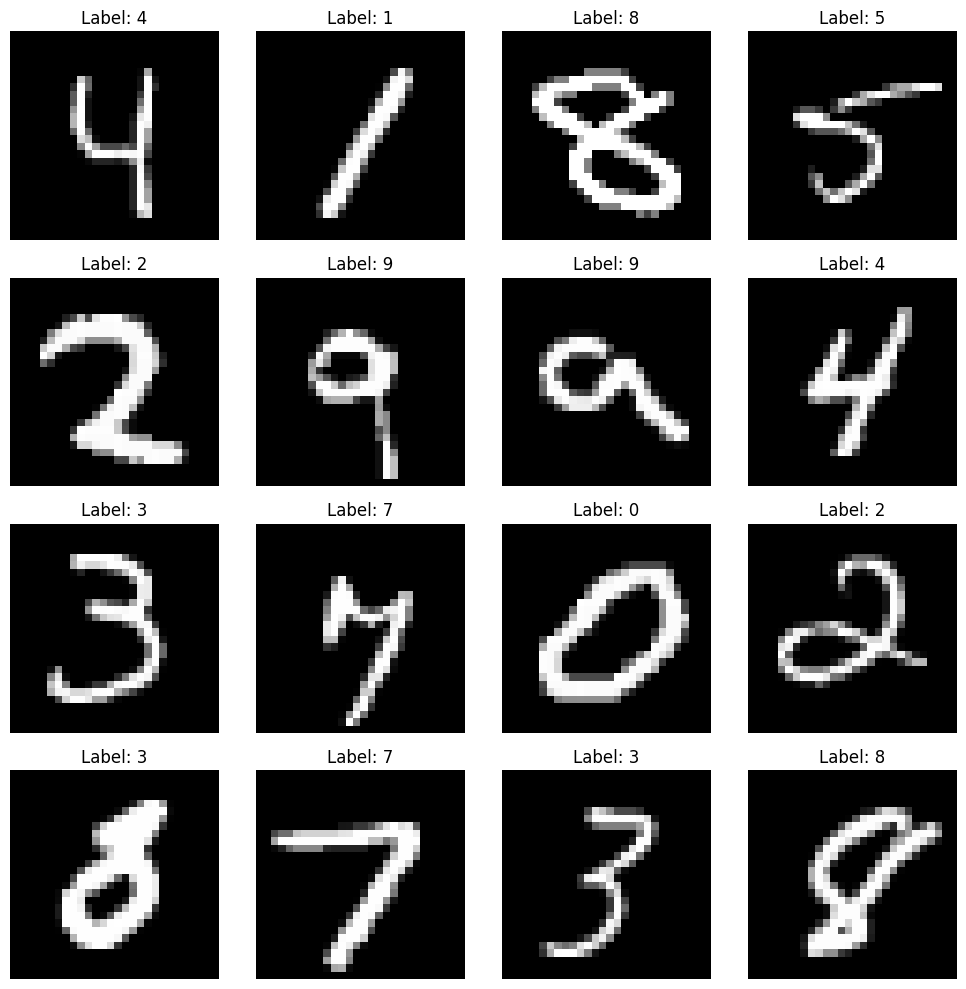

In [6]:
# Visualize first 16 images
num_display = min(16, images.shape[0])
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
axes = axes.flatten()

for idx in range(num_display):
    img = images[idx]
    label = labels[idx].item()
    
    # Convert from [-1, 1] to [0, 1] for display
    img = (img + 1) / 2
    
    # Handle grayscale vs RGB
    if img.shape[0] == 1:
        img = img.squeeze(0)  # Remove channel dimension
        axes[idx].imshow(img, cmap='gray')
    else:
        img = img.permute(1, 2, 0)  # CHW -> HWC
        axes[idx].imshow(img)
    
    axes[idx].set_title(f"Label: {label}")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## Dataset Statistics

In [7]:
# Count samples per class in training set
class_counts = torch.zeros(num_classes, dtype=torch.int64)

for _, labels in train_loader:
    for label in labels:
        class_counts[label] += 1

print("\nClass distribution in training set:")
for class_idx in range(num_classes):
    print(f"  Class {class_idx}: {class_counts[class_idx]} samples")


Class distribution in training set:
  Class 0: 5923 samples
  Class 1: 6742 samples
  Class 2: 5958 samples
  Class 3: 6131 samples
  Class 4: 5842 samples
  Class 5: 5421 samples
  Class 6: 5918 samples
  Class 7: 6265 samples
  Class 8: 5851 samples
  Class 9: 5949 samples


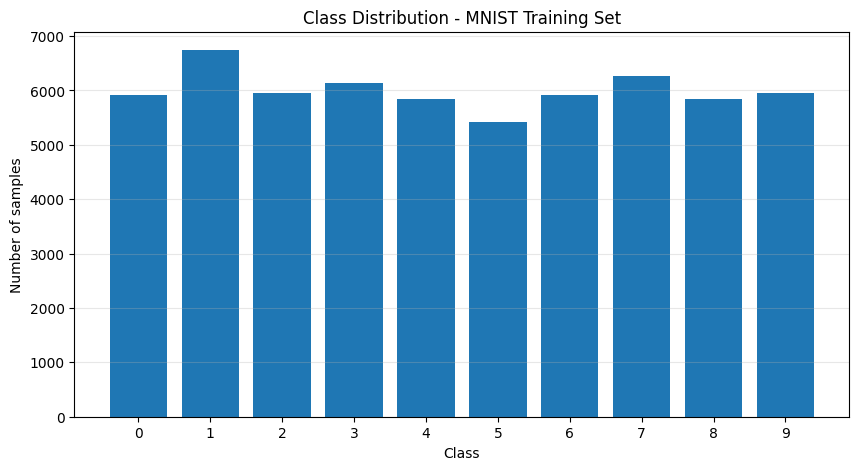

In [8]:
# Visualize class distribution
plt.figure(figsize=(10, 5))
plt.bar(range(num_classes), class_counts.numpy())
plt.xlabel('Class')
plt.ylabel('Number of samples')
plt.title(f'Class Distribution - {info["name"]} Training Set')
plt.xticks(range(num_classes))
plt.grid(axis='y', alpha=0.3)
plt.show()

## Architecture Diffusion-GAN : Explications

### Composants principaux

**1. Générateur G(z):**
- **Entrée:** Vecteur latent `z ~ N(0, I)` (bruit aléatoire, ex: 128 dimensions)
- **Sortie:** Image synthétique `x_g` (ex: 1x28x28 pour MNIST)
- **Rôle:** Créer des images "fausses" qui ressemblent aux vraies

**2. Discriminateur D(y, t):**
- **Entrées:** 
  - `y`: Image bruitée (même dimension que l'image originale)
  - `t`: Timestep de diffusion (entier de 1 à T)
- **Sortie:** Probabilité que `y` soit réelle (scalaire entre 0 et 1)
- **Rôle:** Distinguer images réelles bruitées des images fausses bruitées

**3. Processus de Diffusion (Forward):**
- **Entrée:** Image `x` (réelle ou générée)
- **Processus:** `y = √(ᾱ_t) * x + √(1-ᾱ_t) * σ * ε` où `ε ~ N(0, I)`
- **Sortie:** Image bruitée `y` au timestep `t`
- **Rôle:** Ajouter du bruit contrôlé pour stabiliser l'entraînement

### Entraînement (alterné comme un GAN classique)

**Phase 1: Entraîner le Discriminateur D**
```
1. Prendre un batch d'images réelles x du dataset
2. Générer un batch d'images fausses: x_g = G(z)
3. Choisir un timestep aléatoire t
4. Diffuser les deux types d'images:
   - y_real = √(ᾱ_t) * x + √(1-ᾱ_t) * σ * ε
   - y_fake = √(ᾱ_t) * x_g + √(1-ᾱ_t) * σ * ε
5. Entraîner D à prédire 1 pour (y_real, t) et 0 pour (y_fake, t)
```

**Phase 2: Entraîner le Générateur G**
```
1. Générer des images fausses: x_g = G(z)
2. Choisir un timestep aléatoire t
3. Diffuser les images: y_fake = √(ᾱ_t) * x_g + √(1-ᾱ_t) * σ * ε
4. Passer y_fake dans D(y_fake, t)
5. Backpropager le gradient à travers le processus de diffusion jusqu'à G
6. G apprend à tromper D (maximiser D(y_fake, t))
```

### Pourquoi ça marche mieux ?

- Le bruit diffusé agit comme une **augmentation différentiable**
- À petit `t`: peu de bruit → tâche difficile pour D
- À grand `t`: beaucoup de bruit → tâche plus facile pour D
- D reçoit toujours un signal d'entraînement utile (pas de vanishing gradient)
- G reçoit des gradients stables à travers la chaîne de diffusion

## Exemple concret avec MNIST

Imaginons un batch d'entraînement:

In [9]:
# Simulation du processus de diffusion sur MNIST
import torch

# Paramètres de diffusion (simplifié)
T = 1000  # Nombre de timesteps
beta = torch.linspace(0.0001, 0.02, T)  # Schedule de variance
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)  # ᾱ_t

print(f"Nombre de timesteps: {T}")
print(f"\nExemples de ᾱ_t (ratio signal/bruit):")
print(f"  t=1   : ᾱ_t = {alpha_bar[0]:.4f} (presque pas de bruit)")
print(f"  t=100 : ᾱ_t = {alpha_bar[99]:.4f}")
print(f"  t=500 : ᾱ_t = {alpha_bar[499]:.4f} (moitié signal, moitié bruit)")
print(f"  t=999 : ᾱ_t = {alpha_bar[998]:.4f} (presque que du bruit)")

# Prendre une image réelle
x_real = images[0:1]  # [1, 1, 28, 28]
print(f"\nImage réelle: {x_real.shape}, range [{x_real.min():.2f}, {x_real.max():.2f}]")

Nombre de timesteps: 1000

Exemples de ᾱ_t (ratio signal/bruit):
  t=1   : ᾱ_t = 0.9999 (presque pas de bruit)
  t=100 : ᾱ_t = 0.8970
  t=500 : ᾱ_t = 0.0786 (moitié signal, moitié bruit)
  t=999 : ᾱ_t = 0.0000 (presque que du bruit)

Image réelle: torch.Size([1, 1, 28, 28]), range [-1.00, 1.00]


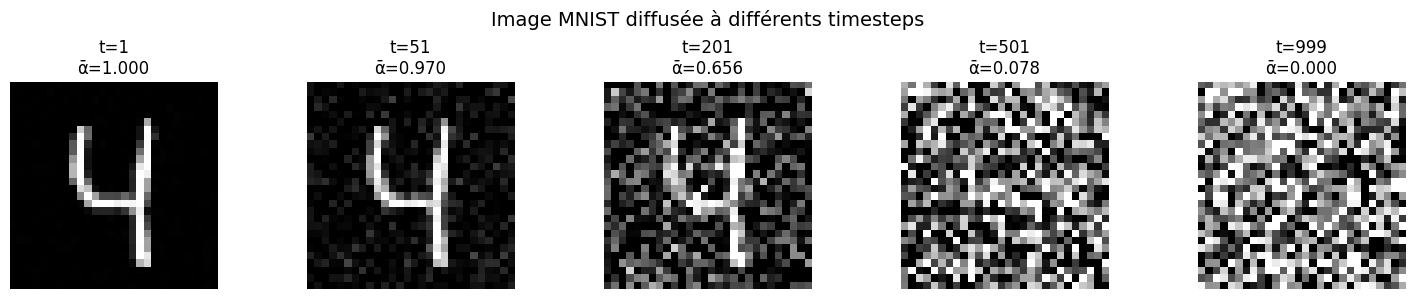

→ Le Discriminateur D(y, t) doit distinguer ces versions bruitées réelles des versions bruitées fausses


In [10]:
# Simuler la diffusion à différents timesteps
def add_noise(x, t, alpha_bar, sigma=1.0):
    """
    Applique le processus de diffusion avant (forward diffusion process).
    
    Ref: Equation (2) du papier Diffusion-GAN: "q(y|x, t) = N(y; sqrt(alpha_bar_t)x, (1 - alpha_bar_t)sigma^2 I)"
    Formule implémentée: y = √(ᾱ_t) * x + √(1-ᾱ_t) * σ * ε
    """
    sqrt_alpha_bar_t = torch.sqrt(alpha_bar[t])
    sqrt_one_minus_alpha_bar_t = torch.sqrt(1 - alpha_bar[t])
    
    # Générer du bruit gaussien
    noise = torch.randn_like(x)
    
    # Appliquer la diffusion
    y = sqrt_alpha_bar_t * x + sqrt_one_minus_alpha_bar_t * noise * sigma
    
    return y

# Visualiser la diffusion à différents timesteps
timesteps = [0, 50, 200, 500, 998]
fig, axes = plt.subplots(1, len(timesteps), figsize=(15, 3))

for idx, t in enumerate(timesteps):
    # Diffuser l'image
    y = add_noise(x_real, t, alpha_bar)
    
    # Afficher
    img = y[0, 0].detach()  # [28, 28]
    img = (img + 1) / 2  # [-1,1] -> [0,1] pour affichage
    img = torch.clamp(img, 0, 1)
    
    axes[idx].imshow(img, cmap='gray')
    axes[idx].set_title(f't={t+1}\nᾱ={alpha_bar[t]:.3f}')
    axes[idx].axis('off')

plt.suptitle('Image MNIST diffusée à différents timesteps', fontsize=14)
plt.tight_layout()
plt.show()

print("→ Le Discriminateur D(y, t) doit distinguer ces versions bruitées réelles des versions bruitées fausses")

## Dataloader pour Diffusion-GAN

Pour l'entraînement, on a juste besoin d'images (pas de labels de classes) :
- **Images uniquement** : `x ~ p_data(x)`
- **Normalisées [-1, 1]** : pour la stabilité du GAN
- **Shufflées** : pour un entraînement stochastique

Le dataloader MNIST actuel convient parfaitement !

In [11]:
# Le dataloader existant est déjà prêt pour Diffusion-GAN !
print("✓ Dataloader MNIST disponible")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Nombre de batches: {len(train_loader)}")
print(f"  - Images normalisées dans [-1, 1]: ✓")
print(f"  - Shuffle activé: ✓")

# Dans la boucle d'entraînement, on utilisera:
print("\n📦 Structure d'un batch d'entraînement:")
x_batch, _ = next(iter(train_loader))  # On ignore les labels pour le GAN
print(f"  - Images x: {x_batch.shape}")
print(f"  - On générera z ~ N(0,I) de dimension [batch_size, latent_dim]")
print(f"  - On échantillonnera t ~ Uniform(1, T)")
print(f"  - On diffusera x et G(z) au timestep t")

✓ Dataloader MNIST disponible
  - Batch size: 64
  - Nombre de batches: 938
  - Images normalisées dans [-1, 1]: ✓
  - Shuffle activé: ✓

📦 Structure d'un batch d'entraînement:
  - Images x: torch.Size([64, 1, 28, 28])
  - On générera z ~ N(0,I) de dimension [batch_size, latent_dim]
  - On échantillonnera t ~ Uniform(1, T)
  - On diffusera x et G(z) au timestep t


## 2. Entrainement

In [38]:
import importlib
import sys

# Force reload des modules
if 'src.models.SNGAN_disc' in sys.modules:
    del sys.modules['src.models.SNGAN_disc']
if 'src.models.SNGAN_gen' in sys.modules:
    del sys.modules['src.models.SNGAN_gen']
if 'src.models.gan_factory' in sys.modules:
    del sys.modules['src.models.gan_factory']

import src.models.gan_factory as gan_factory

generator, discriminator = gan_factory.create_gan_models(
    variant='sngan',
    use_diffusion=False,
    image_channels=1 if info['grayscale'] else 3,
    z_dim=128,
    time_embedding_dim=128,
    gen_channels=[256, 128, 64],
    disc_channels=[64, 128, 256],
)

In [39]:
import tqdm 
T_max = 0
step = 0
C = 1
target_d = 0.6
num_epochs = 5  # Réduit pour tests rapides!
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Move models to device
generator = generator.to(device)
discriminator = discriminator.to(device)

# Criterion
criterion = torch.nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(generator.parameters(), lr=0.0001, betas=(0.0, 0.99))
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=0.0001, betas=(0.0, 0.99))

for epoch in range(num_epochs):
    pbar = tqdm.tqdm(train_loader, desc=f'Epoch [{epoch+1:3d}/{num_epochs}]', 
                     unit='batch', ncols=120, leave=True, position=0, bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}]')
    
    for images, _ in pbar:
        images = images.to(device)
        batch_size = images.size(0)

        # Train discriminator
        optimizer_d.zero_grad()
        optimizer_g.zero_grad()
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        real_outputs = discriminator(images)
        d_loss_real = criterion(real_outputs, real_labels)

        noise = torch.randn(batch_size, 128).to(device)
        fake_images = generator(noise)

        fake_outputs = discriminator(fake_images.detach())
        d_loss_fake = criterion(fake_outputs, fake_labels)

        d_loss = d_loss_real + d_loss_fake

        d_loss.backward()
        optimizer_d.step()

        # Train generator
        optimizer_d.zero_grad()
        optimizer_g.zero_grad()
        fake_outputs = discriminator(fake_images)
        g_loss = criterion(fake_outputs, real_labels)
        g_loss.backward()
        optimizer_g.step()

        # Update progress bar with losses
        pbar.set_postfix({'D_loss': f'{d_loss.item():.4f}', 'G_loss': f'{g_loss.item():.4f}'})

Epoch [  1/5]:  11%|████████▎                                                                    | 102/938 [02:13<18:13]


KeyboardInterrupt: 